In [1]:
import os, glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'results', 'therapeutic', 'drugs', 'pharos')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'therapeutic', 'drugs')

In [3]:
# load pharos data (dset features)
df = pd.read_csv(os.path.join(pth_in, 'results.csv'))

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn) : get_feat(fn) for fn in feat_fn}

# features: target development level (proportion)
df_res, col = dict(), 'Target Development Level'
for src, g in feat_dict.items():
    if src != 'union':
        df_src = df.loc[df.Symbol.isin(g), col].copy()
        df_res[src] = df_src.value_counts(normalize = True)
df_res = pd.concat(df_res, names = ['source', 'TDL'])

In [5]:
c_dict = {
    'GSE162534'         : plt.cm.tab20c(12),
    'GSE229103'         : plt.cm.tab20c(8),
    'rRNAModifications' : plt.cm.tab20c(4)}

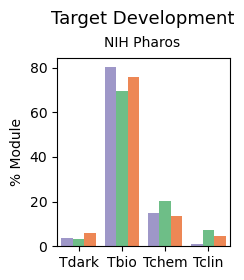

In [7]:
order = ['Tdark','Tbio','Tchem','Tclin']

# plot TDL proportions
fig, ax = plt.subplots(1, 1, figsize = (2.5, 2.75))
df_plt = (df_res.to_frame() * 100)
sns.barplot(df_plt, x = 'TDL',
            y = 'proportion',
            hue = 'source',
            order = order,
            palette = c_dict,
            alpha = .7,
            saturation = 1,
            ax = ax)

ax.legend().set_visible(False)
fig.suptitle('Target Development',
    size = 13, x = .59, y = 1)
fig.text(.59, .865, 'NIH Pharos',
         ha = 'center')
ax.set_ylabel('% Module')
ax.set_xlabel('')
fig.tight_layout()
fn = os.path.join(pth_out, 'pharos.pdf')
plt.savefig(fn, bbox_inches = 'tight')